## **<span style="color:red">동적 웹 페이지 크롤링과 스크래핑</span>**

> **한눈에 보기**
> - Selenium으로 브라우저 열기, 입력·클릭·스크롤·대기
> - 스타벅스 매장 찾기(정적 vs 동적 비교), 여러 페이지 수집
> - 정리 문서: [동적웹수집.md](../동적웹수집.md)

> 한화내일아카데미 10월 13일 수업 실습 노트북입니다. (강사님 자료 `dataexam/exam3.ipynb`)
> - 강의 자료 이미지(강사님이 AI로 만든 그림 등)는 강사님 허락을 받아 그대로 넣었습니다.
> - **📝 정리** 셀은 실행 결과를 보고 직접 정리한 내용입니다.
> - 실습에서 만든 결과 파일(`output/` 아래 CSV, TXT, 이미지)은 다른 사이트의 글과 자료를 수집한 것이라 저장소에 올리지 않았습니다.
> - 셀레니움 셀은 브라우저 창을 직접 조작하는 실습이라 출력이 없는 셀이 많습니다.

![웹 데이터 수집 방법 인포그래픽.png](<attachment:웹 데이터 수집 방법 인포그래픽.png>)
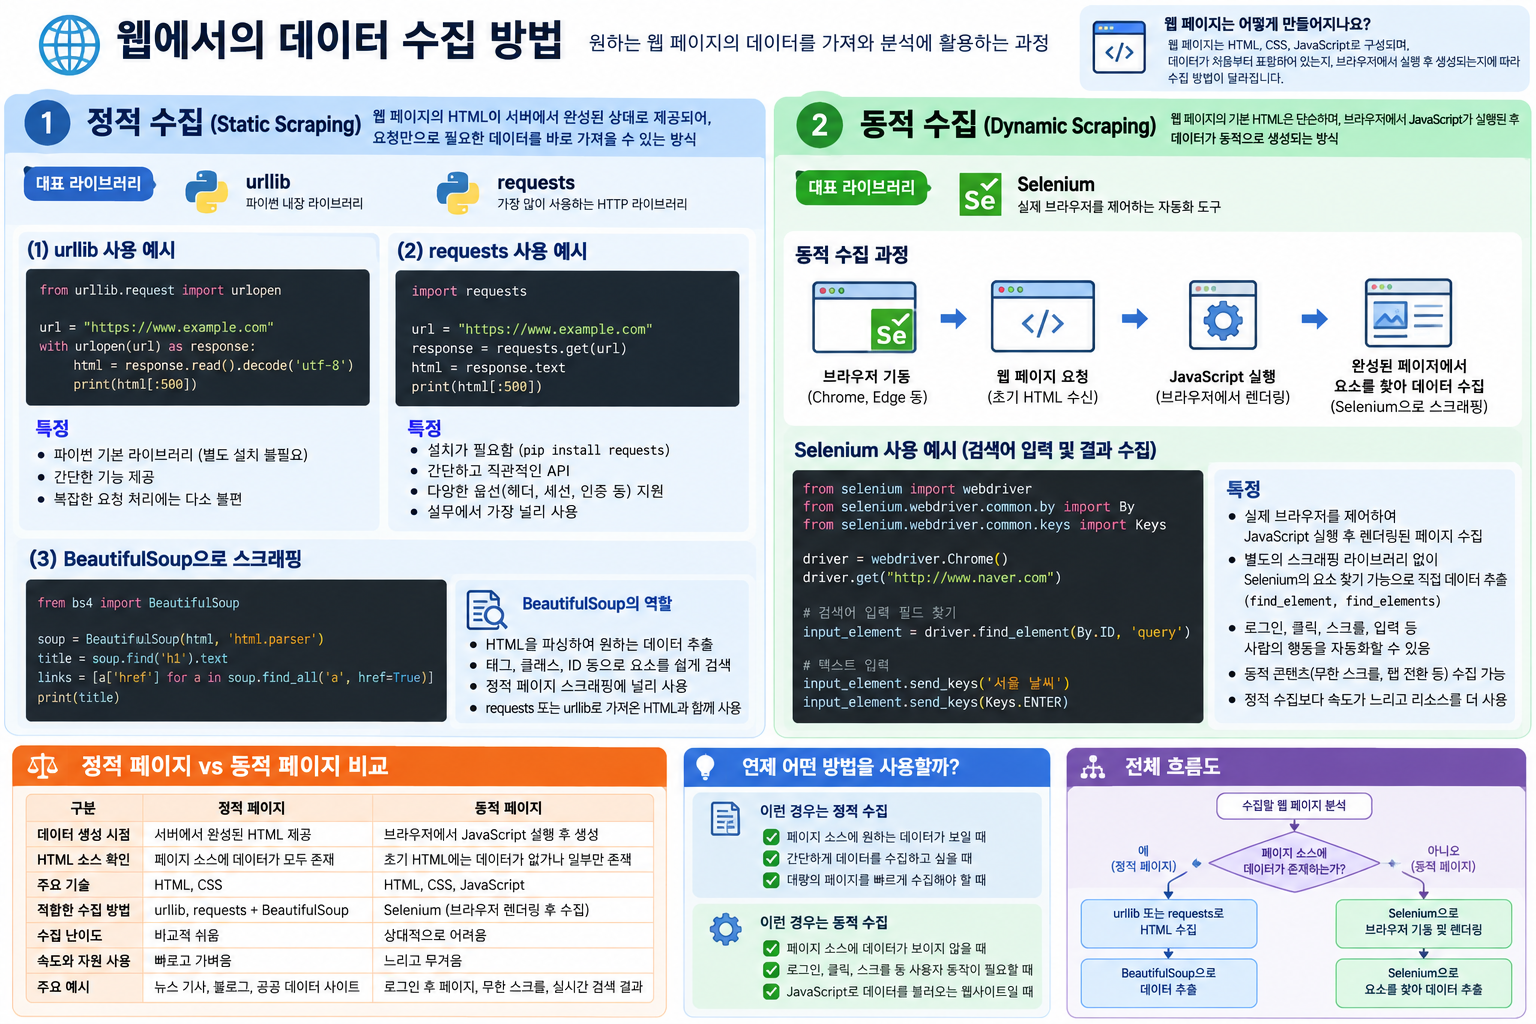

## selenium API 설치

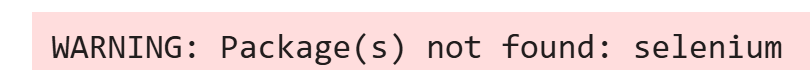

In [1]:
%pip show selenium

Note: you may need to restart the kernel to use updated packages.


In [2]:
# selenium API 를 (재)설치 합시다요~~~~~
%pip install selenium

   ---------------------------------------- 0.0/11.8 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.8 MB 4.8 MB/s eta 0:00:03
   ------ --------------------------------- 1.8/11.8 MB 4.8 MB/s eta 0:00:03
   --------- ------------------------------ 2.9/11.8 MB 4.7 MB/s eta 0:00:02
   ------------- -------------------------- 3.9/11.8 MB 4.7 MB/s eta 0:00:02
   ---------------- ----------------------- 5.0/11.8 MB 4.8 MB/s eta 0:00:02
   -------------------- ------------------- 6.0/11.8 MB 4.8 MB/s eta 0:00:02
   ------------------------ --------------- 7.1/11.8 MB 4.8 MB/s eta 0:00:01
   -------------------------- ------------- 7.9/11.8 MB 4.8 MB/s eta 0:00:01
   ------------------------------- -------- 9.2/11.8 MB 4.8 MB/s eta 0:00:01
   --------------------------------- ------ 10.0/11.8 MB 4.8 MB/s eta 0:00:01
   ------------------------------------- -- 11.0/11.8 MB 4.8 MB/s eta 0:00:01
   ---------------------------------------- 11.8/11.8 MB 4.7 MB/s  0:00:02

   --

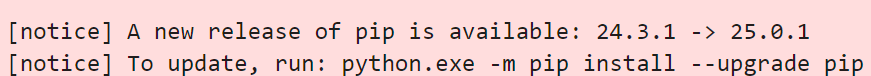

In [3]:
%pip show selenium

Name: selenium
Version: 4.51.0
Summary: Official Python bindings for Selenium WebDriver
Home-page: https://www.selenium.dev
Author: 
Author-email: 
License: Apache-2.0
Location: c:\education_llm\eduvenv\Lib\site-packages
Requires: certifi, trio, trio-websocket, typing_extensions, urllib3, websocket-client
Required-by: 
Note: you may need to restart the kernel to use updated packages.


**📝 정리** — `selenium` 4.51.0을 설치했다. 셀레니움 4.6 이후로는 Selenium Manager가 크롬 드라이버를 자동으로 준비해 줘서, 드라이버 파일을 따로 받지 않고 `webdriver.Chrome()`만으로 브라우저가 열린다.

### Selenium(셀레늄)
- 웹 브라우저의 동작을 자동화하는 데 가장 널리 사용되는 오픈소스 프레임워크입니다. 
- 사람이 직접 브라우저에서 클릭하고, 타이핑하고, 스크롤하는 모든 행위를 파이썬 코드로 대신 수행하게 만들 수 있습니다.
- 크롤링뿐만 아니라 웹 서비스가 정상적으로 작동하는지 테스트하는 자동화 도구로도 필수적인 역할을 합니다.

In [2]:
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
driver = webdriver.Chrome() # selenium 4.16 부터
print("WebDriver 객체 : ", type(driver))

WebDriver 객체 :  <class 'selenium.webdriver.chrome.webdriver.WebDriver'>


In [20]:
driver.get('https://www.naver.com/')

In [21]:
target=driver.find_element(By.CSS_SELECTOR, "[name = 'query']")
target.send_keys('둘리')

In [22]:
target.send_keys(Keys.ENTER)

In [23]:
driver.get('https://www.naver.com/')
target=driver.find_element(By.ID, "query")
target.send_keys('또치')
target.send_keys(Keys.ENTER)

In [24]:
driver.get('https://www.naver.com/')
target=driver.find_element(By.CLASS_NAME, "search_input")
target.send_keys('도우너')
target.send_keys(Keys.ENTER)

**📝 정리** — 같은 네이버 검색창을 CSS 선택자(`[name='query']`), `By.ID`, `By.CLASS_NAME` 세 가지 방법으로 찾아 '둘리', '또치', '도우너'를 검색했다. `send_keys()`로 글자를 입력하고 `Keys.ENTER`로 엔터를 누른다. 다 쓰면 `driver.quit()`로 브라우저를 닫는다.

In [25]:
driver.quit()

### 네이버 검색 창에 일반 텍스트 입력하기

In [26]:
from selenium import webdriver
from selenium.webdriver.common.by import By

driver = webdriver.Chrome()
driver.get("http://www.naver.com")

# 검색어 입력 필드 찾기
input_element = driver.find_element(By.ID, 'query')

# 텍스트 입력
input_element.send_keys('서울 날씨')

### 입력한 텍스트로 검색 진행하기

In [27]:
from selenium import webdriver
from selenium.webdriver.common.by import By

driver = webdriver.Chrome()
driver.get("http://www.naver.com")

# 검색어 입력 필드 찾기
input_element = driver.find_element(By.ID, 'query')

# 텍스트 입력
input_element.send_keys('서울 날씨')
input_element.submit()

### 특수 키 사용하기

In [28]:
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys

driver = webdriver.Chrome()
driver.get("http://www.naver.com")

# 검색어 입력 필드 찾기
input_element = driver.find_element(By.ID, 'query')

# 텍스트 입력
input_element.send_keys('서울 날씨')
input_element.send_keys(Keys.ENTER)

**📝 정리** — 검색 실행은 `submit()`(폼 제출)이나 `send_keys(Keys.ENTER)` 둘 다 가능하다. (이 셀들은 화면에서 브라우저가 움직이는 걸 보는 실습이라 출력이 없다)

### 파이썬에서 입력 받은 값으로 검색하기

In [29]:
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys

driver = webdriver.Chrome()
driver.get("http://www.naver.com")

# 사용자로부터 검색할 단어를 입력받기
search_query = input('검색할 단어를 입력하세요: ')

# 검색어 입력 필드 찾기
input_element = driver.find_element(By.ID, 'query')

# 검색창에 사용자가 입력한 검색어를 입력
input_element.send_keys(search_query)

# ENTER 키를 눌러 검색 실행
input_element.send_keys(Keys.ENTER)

**📝 정리** — `input()`으로 받은 검색어를 그대로 검색창에 넣었다. 코드로 브라우저를 사람처럼 조작할 수 있다는 게 셀레니움의 핵심이다.

### 마우스 클릭하기

In [58]:
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.common.action_chains import ActionChains

driver = webdriver.Chrome()
driver.get('http://www.naver.com')

# 이미지 검색 페이지 버튼 찾기
element_to_click = driver.find_element(By.CSS_SELECTOR, '#shortcutArea > ul > li:nth-child(3) > a > span.service_icon.type_blog')
# 마우스 클릭 실행
element_to_click.click() 

In [83]:
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC

driver = webdriver.Chrome()
driver.get('https://www.naver.com')

# 최대 15초 대기
wait = WebDriverWait(driver, 15)

# 블로그 버튼이 클릭 가능할 때까지 기다림
element_to_click = wait.until(
    EC.element_to_be_clickable(
        (By.CSS_SELECTOR, '#shortcutArea > ul > li:nth-child(3) > a > span.service_icon.type_blog')
    )
)

# 마우스 클릭 실행
element_to_click.click()

**📝 정리** — ⚠️ 위 두 셀 중 첫 번째 셀의 주석은 "이미지 검색 페이지 버튼"이지만 선택자는 `span.service_icon.type_blog`, 즉 **블로그** 바로가기다. 두 번째 셀은 같은 버튼을 `WebDriverWait(driver, 15)` + `element_to_be_clickable`로 **클릭할 수 있을 때까지 기다렸다가** 클릭한다. 페이지가 다 그려지기 전에 찾으면 요소를 못 찾는 오류가 나기 때문에, 이렇게 명시적으로 기다리는 쪽이 안정적이다.

### 스크롤바 이동하기

In [59]:
from selenium import webdriver

driver = webdriver.Chrome()
driver.get('https://www.naver.com')

# y축 방향으로 500 픽셀만큼 이동
driver.execute_script('window.scrollTo(0, 1000)')

In [60]:
from selenium import webdriver

driver = webdriver.Chrome()
driver.get('https://www.naver.com')

# 페이지 최하단으로 스크롤
driver.execute_script('window.scrollTo(0, document.body.scrollHeight)')

**📝 정리** — ⚠️ 위 두 셀 중 첫 번째 셀의 주석은 "500 픽셀"인데 코드는 `scrollTo(0, 1000)`이라 1000픽셀 이동한다. 두 번째 셀처럼 `document.body.scrollHeight`를 주면 맨 아래로 간다. 셀레니움은 `execute_script()`로 페이지 안에서 자바스크립트를 실행할 수 있다.

### 특정 요소 위치로 스크롤바 이동하기

In [81]:
from selenium import webdriver

driver = webdriver.Chrome()
driver.get('https://www.naver.com')

# 페이지에서 [증시] 코너의 [증시] 요소 찾기
element = driver.find_element(By.PARTIAL_LINK_TEXT, '증시')

# 해당 요소가 화면 중앙으로 오도록 부드럽게 스크롤바를 조정
driver.execute_script("arguments[0].scrollIntoView({behavior: 'smooth', block: 'center', inline: 'center'});", element)

In [82]:
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC

driver = webdriver.Chrome()
driver.get("https://www.naver.com")

# 최대 15초 동안 증시 링크가 나타나기를 기다림
wait = WebDriverWait(driver, 15)

element = wait.until(
    EC.presence_of_element_located(
        (By.PARTIAL_LINK_TEXT, "증시")
    )
)

# 해당 요소를 화면 중앙으로 스크롤
driver.execute_script(
    "arguments[0].scrollIntoView({behavior: 'smooth', block: 'center', inline: 'center'});",
    element
)

**📝 정리** — `scrollIntoView()`로 특정 요소('증시' 링크)가 화면 가운데 오도록 스크롤했다. 첫 번째 셀은 `By`를 import하지 않았는데도 실행된 건 앞 셀에서 이미 import했기 때문이다(커널을 새로 시작하고 이 셀만 실행하면 `NameError`). 두 번째 셀은 import와 기다리기까지 넣어서 혼자 실행해도 된다.

### 스크린샷하기

In [84]:
from selenium import webdriver
import time

driver = webdriver.Chrome()
driver.get('https://www.google.com')

driver.save_screenshot('output/full_page_screenshot.png')
time.sleep(3)
driver.quit()

In [10]:
from selenium import webdriver

driver = webdriver.Chrome()
driver.get('https://www.google.com')

# 구글 메인 로고 요소 찾아 캡처
element = driver.find_element(By.CSS_SELECTOR, '#sI1XGe > div > svg')
element.screenshot('output/element_screenshot.png')
driver.quit()

**📝 정리** — `save_screenshot()`은 브라우저 화면 전체를, `element.screenshot()`은 요소 하나(구글 로고)만 이미지로 저장한다. 로고 선택자 `#sI1XGe`처럼 자동 생성된 id는 사이트가 바뀌면 달라지기 쉬워서 오래 쓰기 어렵다. (이 셀도 `By` import는 앞 셀에 의존)

#### 스타벅스의 매장 정보를 볼 수 있는 사이트 입니다.
##### https://www.istarbucks.co.kr/store/store_map.do

In [11]:
import urllib.request
from bs4 import BeautifulSoup
#서버 접속
server = urllib.request.urlopen("https://www.istarbucks.co.kr/store/store_map.do")

response =server.read().decode()
bs = BeautifulSoup(response, "html.parser")
li = bs.find_all('li', class_="quickResultLstCon")
print(li)

[]


**📝 정리** — `urllib`으로 스타벅스 매장 찾기 페이지를 받아 매장 목록(`li.quickResultLstCon`)을 찾았더니 **빈 리스트 `[]`**가 나왔다. 매장 목록은 페이지가 열린 뒤 자바스크립트가 서버에서 데이터를 받아 그리는 **동적 콘텐츠**라서, 처음 받은 HTML에는 없기 때문이다.

In [12]:
from selenium import webdriver
from selenium.webdriver.common.by import By

driver = webdriver.Chrome()
driver.get("https://www.istarbucks.co.kr/store/store_map.do")

In [13]:
target=driver.find_element(By.CLASS_NAME, "quickResultLstCon")

print(type(target))
print(type(target.text))
print(target.text)


<class 'selenium.webdriver.remote.webelement.WebElement'>
<class 'str'>
무교로
서울특별시 중구 무교로 15 (무교동)
1522-3232
리저브 매장 2번


**📝 정리** — 같은 페이지를 셀레니움으로 열면 실제 브라우저가 자바스크립트까지 실행하므로 매장 정보(무교로 매장 주소, 전화번호)를 찾을 수 있다. 이게 정적 수집(requests/urllib)과 동적 수집(셀레니움)의 차이다. `find_element()`는 첫 번째 요소 하나만 돌려준다.

In [14]:
driver.quit()

In [15]:
from selenium import webdriver
from selenium.webdriver.common.by import By

driver = webdriver.Chrome()
driver.get('http://unico2013.dothome.co.kr/crawling/exercise_css.html')
print('-----------------------------')
byTagName = driver.find_element(By.TAG_NAME,'h1')
print(type(byTagName))
print(byTagName.tag_name, ":", byTagName.text)
print('-----------------------------')
byTagNames = driver.find_elements(By.TAG_NAME, 'h2')
print(type(byTagNames))
for tagName in byTagNames :
   print(tagName.tag_name, ":", tagName.text)


-----------------------------
<class 'selenium.webdriver.remote.webelement.WebElement'>
h1 : CSS 선택자 학습
-----------------------------
<class 'list'>
h2 : 교육과정 소개
h2 : 웹 클라이언트 기술
h2 : 학습 순서(수집)


In [16]:
byClassName = driver.find_element(By.CLASS_NAME,'subtitle')
print(type(byClassName))
print(byClassName.tag_name, ":", byClassName.text)
print('-----------------------------')
byClassNames = driver.find_elements(By.CLASS_NAME, 'subtitle')
print(type(byClassNames))
for className in byClassNames :
   print(className.tag_name, ":", className.text)

<class 'selenium.webdriver.remote.webelement.WebElement'>
h2 : 웹 클라이언트 기술
-----------------------------
<class 'list'>
h2 : 웹 클라이언트 기술
h2 : 학습 순서(수집)


In [17]:
byId = driver.find_element(By.ID,'btype')
print(type(byId))
print(byId.tag_name, ":", byId.text)
print('-----------------------------')
byLinkText = driver.find_element(By.LINK_TEXT,'파이썬 학습 사이트')
print(type(byLinkText))
print(byLinkText.tag_name, ":", byLinkText.text)
print('-----------------------------')
byPLinkText = driver.find_elements(By.PARTIAL_LINK_TEXT,'사이트')
print(type(byPLinkText))
for linkText in byPLinkText :
   print(linkText.tag_name, ":", linkText.text)

<class 'selenium.webdriver.remote.webelement.WebElement'>
li : HTML5
-----------------------------
<class 'selenium.webdriver.remote.webelement.WebElement'>
a : 파이썬 학습 사이트
-----------------------------
<class 'list'>
a : HTML, CSS, JavaScript 학습 사이트
a : 파이썬 학습 사이트


In [18]:
byCss1 = driver.find_element(By.CSS_SELECTOR, 'section>h2')
print(type(byCss1))
print(byCss1.tag_name, ":", byCss1.text)
print('-----------------------------')
byCss2 = driver.find_element(By.CSS_SELECTOR,'aside>h2')
print(type(byCss2))
print(byCss2.tag_name, ":", byCss2.text)
print('-----------------------------')
byCss3 = driver.find_element(By.CSS_SELECTOR,'body > section > article > ul > li:nth-child(3)')
print(type(byCss3))
print(byCss3.tag_name, ":", byCss3.text)
print('-----------------------------')
byCss4 = driver.find_elements(By.CSS_SELECTOR,'ul>li.atype')
print(type(byCss4))
for byCss in byCss4 :
   print(byCss.tag_name, ":", byCss.text)

<class 'selenium.webdriver.remote.webelement.WebElement'>
h2 : 교육과정 소개
-----------------------------
<class 'selenium.webdriver.remote.webelement.WebElement'>
h2 : 학습 순서(수집)
-----------------------------
<class 'selenium.webdriver.remote.webelement.WebElement'>
li : JavaScript
-----------------------------
<class 'list'>
li : CSS3
li : Ajax


In [19]:
byXpath1 = driver.find_element(By.XPATH,'//*[@id="f_subtitle"]')
print(type(byXpath1))
print(byXpath1.tag_name, ":", byXpath1.text)
print('-----------------------------')
byXpath2 = driver.find_element(By.XPATH,'/html/body/section/article/ul/li[3]')
print(type(byXpath2))
print(byXpath2.tag_name, ":", byXpath2.text)
print('-----------------------------')
byXpath3 = driver.find_elements(By.XPATH,'//ul/li[@class="atype"]')
print(type(byXpath3))
for byXpath in byXpath3 :
   print(byXpath.tag_name, ":", byXpath.text)

<class 'selenium.webdriver.remote.webelement.WebElement'>
h2 : 교육과정 소개
-----------------------------
<class 'selenium.webdriver.remote.webelement.WebElement'>
li : JavaScript
-----------------------------
<class 'list'>
li : CSS3
li : Ajax


In [20]:
byXpath1 = driver.find_element(By.XPATH,'//div/img')
print(type(byXpath1))
print(byXpath1.tag_name, ":", byXpath1.get_attribute('src'))
print('-----------------------------')
byXpath2 = driver.find_elements(By.XPATH,'/html/body/header/nav/a')
print(type(byXpath2))
for byXpath in byXpath2 :
   print(byXpath.tag_name, ":", byXpath.get_attribute('href'))

<class 'selenium.webdriver.remote.webelement.WebElement'>
img : https://www.python.org/static/img/python-logo.png
-----------------------------
<class 'list'>
a : https://www.w3schools.com/
a : https://www.python.org/


**📝 정리** — 셀레니움에서도 태그 이름, 클래스, id, 링크 텍스트(`LINK_TEXT` 전체 일치 / `PARTIAL_LINK_TEXT` 부분 일치), CSS 선택자, XPath로 요소를 찾을 수 있다. CSS `section>h2`와 XPath `//*[@id="f_subtitle"]`처럼 다른 방법으로 같은 요소를 찾을 수 있고, `find_element()`는 하나, `find_elements()`는 리스트를 돌려준다. 속성 값은 `get_attribute('src')`로 꺼낸다.

In [21]:
driver.quit()

In [22]:
from selenium import webdriver
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.common.by import By
import time

url = "https://www.megabox.co.kr/movie-detail/comment?rpstMovieNo=21033000"
driver =  webdriver.Chrome()
driver.get(url)

points = list()
recommends = list()
txts = list()

# 1페이지 정보
time.sleep(2)
points.extend([p.text for p in driver.find_elements(By.CLASS_NAME, 'story-point')])
recommends.extend([r.text for r in driver.find_elements(By.CLASS_NAME,'story-recommend')])
txts.extend([t.text for t in driver.find_elements(By.CLASS_NAME,'story-txt')])

# 2~30 페이지 정보
for page in range(2, 31):
    if page % 10 == 1:
        next_btn = driver.find_element(By.CSS_SELECTOR, "#contentData > div > div.movie-idv-story > nav > a.control.next")
        next_btn.click()
    else:
        page_btn = driver.find_element(By.LINK_TEXT, str(page))
        page_btn.click()
    #driver.implicitly_wait(3)
    time.sleep(2)
    
    points.extend([p.text for p in driver.find_elements(By.CLASS_NAME,'story-point')])
    recommends.extend([r.text for r in driver.find_elements(By.CLASS_NAME,'story-recommend')])
    txts.extend([t.text for t in driver.find_elements(By.CLASS_NAME,'story-txt')])
    
print("수집완료~~~")

with open('output/movie.csv', "wt", encoding="utf-8") as f:
    f.write("score,genre,review\n")
    for p, r, t in zip(points, recommends, txts):
        t = '"' + t.replace('"', '""') + '"'
        f.write(",".join([p, r, t])+"\n")   


수집완료~~~


**📝 정리** — 메가박스 영화 관람평 30페이지(페이지당 10건)를 클릭하며 모아 300건을 `output/movie.csv`로 저장했다. 10페이지마다 번호 버튼이 바뀌어서 `page % 10 == 1`일 때는 '다음' 버튼을 누른다. 결과 파일을 확인해 보니 300행 × 3열이고 평점 10점이 211건으로 가장 많았다.

확인한 점: 두 번째 열 이름을 `genre`로 했지만 실제로는 장르가 아니라 **관람 포인트**(`story-recommend`, 예: `스토리`, `배우`, `연출`)가 들어간다. 포인트를 여러 개 고른 관람평은 `스토리배우`처럼 구분자 없이 붙어서 저장됐다. 리뷰 본문은 큰따옴표를 `""`로 바꿔 감싸서 CSV가 깨지지 않게 처리했다. (수집한 관람평은 다른 사람의 글이라 저장소에 올리지 않았다)

In [23]:
from selenium import webdriver
from selenium.webdriver.common.by import By

driver = webdriver.Chrome()
driver.get("https://www.yes24.com/Product/Goods/30666296")
import time
temp_list = []
time.sleep(3)
stopFlag = False

driver.execute_script("window.scrollTo(0, 2000);");
time.sleep(2)
driver.execute_script("window.scrollTo(0, 4000);");
time.sleep(2)
driver.execute_script("window.scrollTo(0, 6000);");
time.sleep(2)
driver.execute_script("window.scrollTo(0, 8000);");
time.sleep(2)
driver.execute_script("window.scrollTo(0, 10000);");
time.sleep(2)
driver.execute_script("window.scrollTo(0, 12000);");
time.sleep(2)
driver.execute_script("window.scrollTo(0, 14000);");
total = driver.find_element(By.CSS_SELECTOR, '#total > a')
time.sleep(2)
driver.execute_script("arguments[0].click();", total)
time.sleep(2)

while True :
  for n in range(4, 13) :   
    print(n)
    readLinks = driver.find_elements(By.CSS_SELECTOR, '#infoset_reviewContentList    div.reviewInfoBot.crop > a > div > span')
    for readlink in readLinks :
      #readlink.click()
      driver.execute_script("arguments[0].click();", readlink)
      time.sleep(2)
    
    reviewList = driver.find_elements(By.CSS_SELECTOR, '#infoset_reviewContentList div.reviewInfoBot.origin div.review_cont')
    time.sleep(2)

    for review in reviewList :    
      temp_list.append(review.text)
    
    if len(reviewList) < 5:
      stopFlag = True
      break
        
    if stopFlag == True :
      break
    
    linkurl = '#infoset_reviewContentList > div.review_sort.sortBot > div.review_sortLft > div > a:nth-child('+str(n)+')'    
    linkNum = driver.find_element(By.CSS_SELECTOR, linkurl)
    linkNum.click()   
    time.sleep(2)
        
  dimDom = '#infoset_reviewContentList > div.review_sort.sortBot > div.review_sortLft > div > a.bgYUI.dim' 
  try :
    driver.find_element(By.CSS_SELECTOR, dimDom)
    break
  except :
    nextPage = '#infoset_reviewContentList > div.review_sort.sortBot > div.review_sortLft > div > a.bgYUI.next'
  linkNum = driver.find_element(By.CSS_SELECTOR, nextPage)  
  linkNum.click()
  time.sleep(2)

print("크롤링 완료~~~~")
wfile = open("output/yes24file.txt","w", encoding="utf-8") 
wfile.writelines(temp_list) 
wfile.close()
time.sleep(10)
#driver.quit()

4
5
6
7
8
9
10
11
12
4
5
6
7
8
9
10
11
12
4
5
6
7
8
크롤링 완료~~~~


**📝 정리** — YES24 도서 상세 페이지의 리뷰를 모았다. 리뷰 영역은 스크롤해야 불러와져서 `scrollTo`로 조금씩 내리고, '더보기' 링크는 `execute_script("arguments[0].click();", 요소)`로 자바스크립트 클릭을 했다(일반 `click()`은 다른 요소에 가려지면 실패할 수 있음). 페이지 번호(4~12번째 링크)를 누르다가 마지막 묶음이면 멈춘다.

⚠️ `writelines(temp_list)`는 리스트 항목 사이에 줄바꿈을 넣지 않아서, 앞 리뷰의 끝과 다음 리뷰의 시작이 붙어서 저장된다. `"\n".join(temp_list)`로 쓰거나 항목마다 `"\n"`을 붙여야 리뷰를 다시 나눌 수 있다. (수집한 리뷰는 저장소에 올리지 않았다)

### <span style='color:blue; font-weight:bold'>동적 웹페이지 수집에 대해 학습했습니다.</span>

## 🔁 복습 질문

<details>
<summary>1. <code>find_element(By.CSS_SELECTOR, ...)</code>로 요소를 못 찾으면 먼저 의심할 것은?</summary>

아직 페이지가 다 그려지지 않았을 수 있다. 명시적 대기를 쓰고, iframe 안에 있는지도 확인한다.
</details>

<details>
<summary>2. 수집이 끝나면 꼭 해야 할 일은?</summary>

`driver.quit()`으로 브라우저를 닫는다. 안 닫으면 브라우저 프로세스가 계속 남는다.
</details>
